In this model, I will add: \
\
Averages after steady state \
\
We're given n as a function of t in the instructions. Based on previous experiments that also have exponential behaviour, we know that any exp^(-t/tau) has a characteristic relaxation time - after time tau, the system returns to an equilibrium. \
\
Given that:
$$ n(t) = \frac{N}{2} [ 1 + e^{\frac{-2t}{N}} ] $$

The relaxation time is proportional to N.

In [7]:
import numpy as np
import random
import scipy.special
from scipy.special import factorial
import matplotlib.pyplot as plt


# The below commands make the font and image size bigger
plt.rcParams.update({'font.size': 18})
plt.rcParams["figure.figsize"] = (16,9)

In [8]:
k_b = 1.380649e-23                                        # Boltzmann constant for entropy calculation

In [38]:
def ehrenfest_model(N, t_max, t_step):
    pstate = np.zeros(N)                                        # state vector
    time_points = np.arange(0, t_max, t_step)                   # x-axis for plotting
    left_points = []                                            # empty array for left y-values
    right_points = []                                           # empty array for right y-values
    entropy = []

    for i in range(t_max):
    
        n = np.count_nonzero(pstate == 0)                       # keeps track of # particles on the left
        n_right = np.count_nonzero(pstate)                      # keeps track of # particles on the right
        e_coeff =  scipy.special.binom(N, n)
    
        left_points.append(n)
        right_points.append(n_right)
        entropy.append(e_coeff)
    
        rnd = np.random.choice(N)                               # selects a random particle

        if pstate[rnd] == 0:                                    # if particle is on the left, calculates transition prob to right
            if np.random.random() < (n / N):                    # then we generate a random number - if it's smaller than my transition probability
                pstate[rnd] = 1                                 # then the particles moves to the right
        else:
            if np.random.random() < (1 - (n / N)):              # if the particle is on the right, it's a different probability
                pstate[rnd] = 0                                 # and the state changes to left if transition probability > random number

    return n, n_right, time_points, left_points, right_points, N, entropy

In [49]:
t_eqm = N
t_eqm_1 = 2*N
t_eqm_2 = 3*N

steady_state = np.array(left_points[t_eqm:])
steady_state_1 = np.array(left_points[t_eqm_1:])
steady_state_2 = np.array(left_points[t_eqm_2:])

print(np.mean(steady_state))
print(np.mean(steady_state_1))
print(np.mean(steady_state_2))

print(np.var(steady_state))
print(np.var(steady_state_1))
print(np.var(steady_state_2))

print(np.std(steady_state))
print(np.std(steady_state_1))
print(np.std(steady_state_2))

# It would seem to me that anything after N is pretty good.

504.82722222222225
501.977125
502.81114285714284
190.90692561728395
117.34435173437498
122.24233297959184
13.816907237775172
10.832559796021206
11.056325473664016


In [48]:
n, n_right, time_points, left_points, right_points, N, entropy = ehrenfest_model(1000, 10000, 1)

Final count of particles on the left: 480
Final count of particles on the right: 520
The standard deviation of the fluctuations is: 15.811388300841896


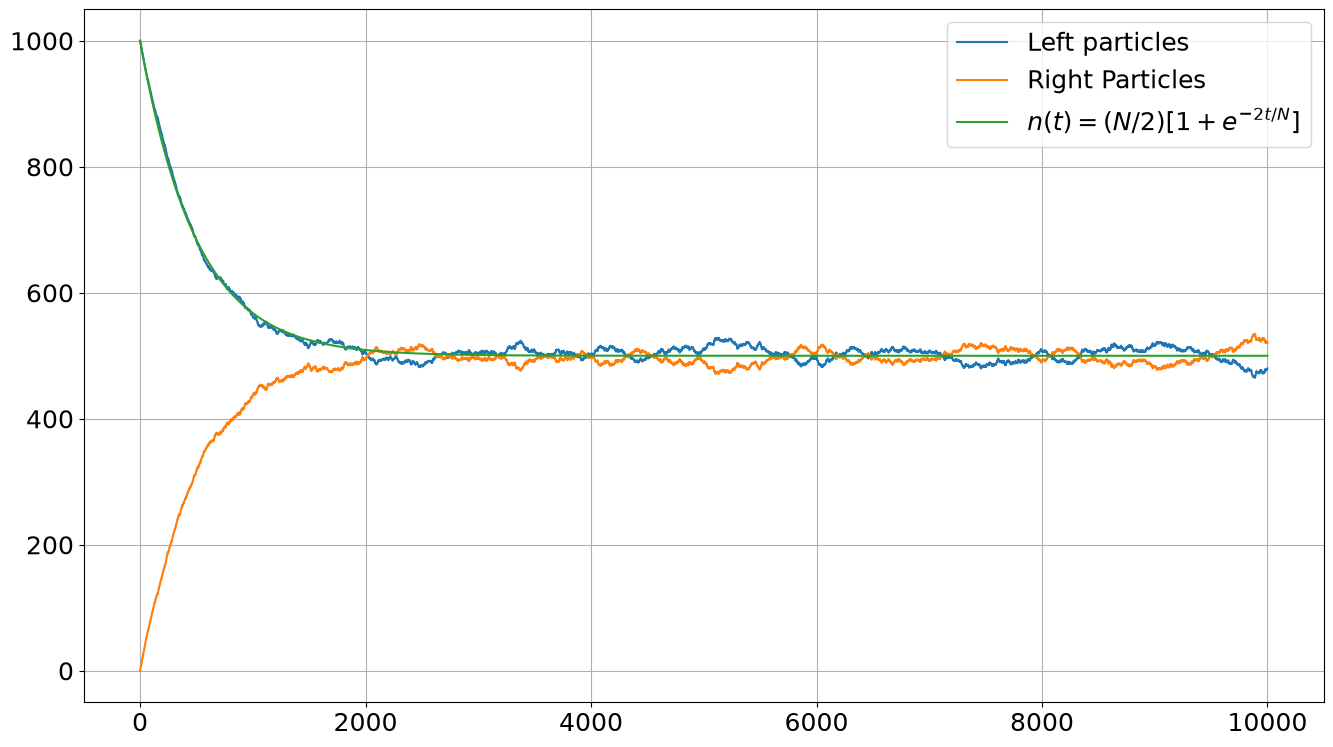

In [50]:
# print(pstate)
print("Final count of particles on the left:", n)
print("Final count of particles on the right:", n_right)
print("The standard deviation of the fluctuations is:", np.sqrt(N)/2)

# Plotting
plt.plot(time_points, left_points)
plt.plot(time_points, right_points)
plt.plot(time_points, (N / 2) * (1 + np.exp((-2*time_points) / N)))
plt.grid(True)
plt.legend(['Left particles', 'Right Particles', '$n(t) = (N/2)[ 1 + e^{-2t/N}]$'])

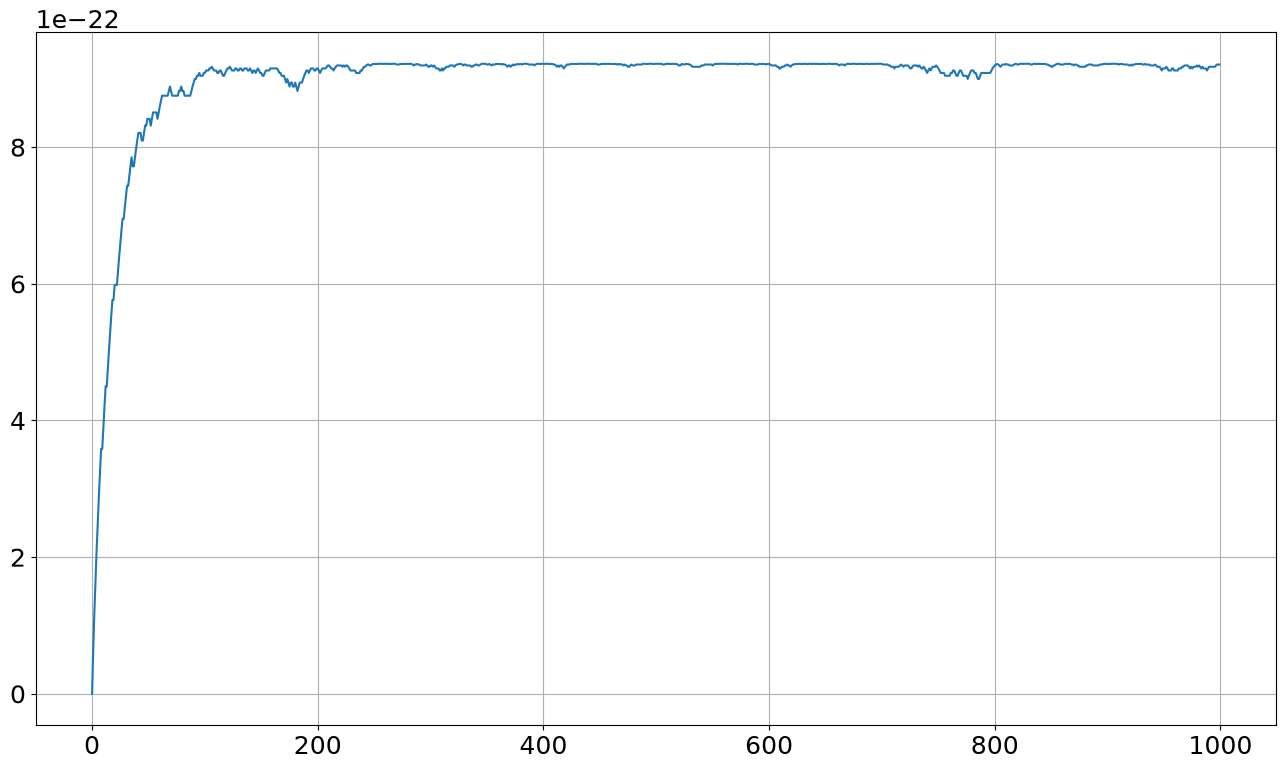

In [27]:
plt.plot(time_points, (k_b * np.log(entropy)))
plt.grid(True)